# Week 4: Data Analysis with Pandas
**Assignments: 46, 47, 48**

Analyzing, cleaning, and finding correlations in data with Pandas.

## Required Libraries and Modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Dataset
The same exercise dataset used in Week 3 (Assignment 45): workout duration, pulse, max pulse, and calories burned.

In [2]:
np.random.seed(0)
rows = 30

df = pd.DataFrame({
    "Duration": np.random.choice([45, 60, 90], size=rows),
    "Pulse": np.random.randint(90, 130, size=rows),
})
df["Maxpulse"] = df["Pulse"] + np.random.randint(10, 40, size=rows)
df["Calories"] = (df["Duration"] * 4.5 + df["Pulse"] * 0.8
                  + np.random.normal(0, 20, size=rows)).round(1)

print(df.shape)

(30, 4)


## Assignment 46: Analyzing Data (Week 4, Day 1)
Use `head()`, `tail()`, `info()`, and `describe()` to get a quick overview of a DataFrame.

In [3]:
print("First 10 rows:")
print(df.head(10))

print("\nLast 5 rows:")
print(df.tail())

First 10 rows:
   Duration  Pulse  Maxpulse  Calories
0        45    119       152     323.0
1        60    109       130     333.8
2        45    109       133     311.0
3        60    104       132     339.2
4        60    129       166     376.1
5        90    122       132     510.6
6        45     91       115     275.8
7        90     99       112     505.3
8        45    122       153     298.6
9        45    121       143     286.0

Last 5 rows:
    Duration  Pulse  Maxpulse  Calories
25        90     91       116     447.8
26        45     91       121     250.7
27        90    129       142     512.1
28        45    125       161     282.5
29        60    128       161     365.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  30 non-null     int64  
 1   Pulse     30 non-null     int32  
 2   Maxpulse  30 non-null     int32  
 3   Calories  30 non-null     float64
dtypes: float64(1), int32(2), int64(1)
memory usage: 852.0 bytes


In [5]:
df.describe()

,Duration,Pulse,Maxpulse,Calories
count,30.000000,30.000000,30.000000,30.000000
mean,61.000000,110.866667,134.400000,362.526667
std,17.587221,13.984556,17.369414,83.650459
min,45.000000,90.000000,104.000000,250.700000
25%,45.000000,99.250000,121.000000,299.050000
50%,60.000000,111.000000,133.000000,343.200000
75%,60.000000,123.500000,148.750000,374.925000
max,90.000000,129.000000,166.000000,538.600000


## Assignment 47: Cleaning Data (Week 4, Day 1)
Fix the four common problems in a dataset:
1. **Empty cells**
2. **Data in the wrong format**
3. **Wrong data**
4. **Duplicates**

In [6]:
dirty = pd.DataFrame({
    "Duration": [60, 60, 60, 45, 45, 60, 60, 450, 30, 60, 60, 60],
    "Date": ["2020/12/01", "2020/12/02", "2020/12/03", "2020/12/04", "2020/12/05", "2020/12/06",
             "2020/12/07", "2020/12/08", "2020/12/09", None, "2020/12/11", "20201212"],
    "Pulse": [110, 117, 103, 109, 117, 102, 110, 104, 109, 98, 103, 103],
    "Maxpulse": [130, 145, 135, 175, 148, 127, 136, 134, 133, 124, 147, 147],
    "Calories": [409.1, 479.0, 340.0, 282.4, 406.0, 300.0, 374.0, 253.3, None, 269.0, None, 329.3],
})
dirty = pd.concat([dirty, dirty.iloc[[3]]], ignore_index=True)   # add a duplicate row

print(dirty.to_string())

    Duration        Date  Pulse  Maxpulse  Calories
0         60  2020/12/01    110       130     409.1
1         60  2020/12/02    117       145     479.0
2         60  2020/12/03    103       135     340.0
3         45  2020/12/04    109       175     282.4
4         45  2020/12/05    117       148     406.0
5         60  2020/12/06    102       127     300.0
6         60  2020/12/07    110       136     374.0
7        450  2020/12/08    104       134     253.3
8         30  2020/12/09    109       133       NaN
9         60        None     98       124     269.0
10        60  2020/12/11    103       147       NaN
11        60    20201212    103       147     329.3
12        45  2020/12/04    109       175     282.4


### 1. Empty cells

In [7]:
# option A: remove rows with empty cells (returns a new DataFrame)
print("Rows before:", len(dirty), "| rows after dropna():", len(dirty.dropna()))

# option B: replace empty cells with a fixed value
filled = dirty.copy()
filled["Calories"] = filled["Calories"].fillna(130)

# option C: replace empty cells with the mean, median, or mode of the column
mean_value = dirty["Calories"].mean()
median_value = dirty["Calories"].median()
mode_value = dirty["Calories"].mode()[0]
print(f"mean = {mean_value:.2f}, median = {median_value:.2f}, mode = {mode_value}")

clean = dirty.copy()
clean["Calories"] = clean["Calories"].fillna(mean_value)
print(clean["Calories"].isna().sum(), "empty Calories cells left")

Rows before: 13 | rows after dropna(): 10
mean = 338.59, median = 329.30, mode = 282.4
0 empty Calories cells left


### 2. Data in the wrong format

In [8]:
# convert every date to a proper datetime (handles "20201212" too)
clean["Date"] = pd.to_datetime(clean["Date"], format="mixed")

# a missing date cannot be guessed, so drop that row
clean = clean.dropna(subset=["Date"])
print(clean[["Date"]].tail())

         Date
7  2020-12-08
8  2020-12-09
10 2020-12-11
11 2020-12-12
12 2020-12-04


### 3. Wrong data

In [9]:
# a workout of 450 minutes is clearly a typo
print(clean[clean["Duration"] > 120])

# option A: replace the value
clean.loc[clean["Duration"] > 120, "Duration"] = 120

# option B (shown for reference): remove rows with wrong data
#   for x in clean.index:
#       if clean.loc[x, "Duration"] > 120:
#           clean.drop(x, inplace=True)

print("Max duration now:", clean["Duration"].max())

   Duration       Date  Pulse  Maxpulse  Calories
7       450 2020-12-08    104       134     253.3
Max duration now: 120


### 4. Duplicates

In [10]:
print("Duplicate rows:")
print(clean.duplicated().value_counts())

clean = clean.drop_duplicates()
print("\nCleaned data:")
print(clean.to_string())

Duplicate rows:
False    11
True      1
Name: count, dtype: int64

Cleaned data:
    Duration       Date  Pulse  Maxpulse    Calories
0         60 2020-12-01    110       130  409.100000
1         60 2020-12-02    117       145  479.000000
2         60 2020-12-03    103       135  340.000000
3         45 2020-12-04    109       175  282.400000
4         45 2020-12-05    117       148  406.000000
5         60 2020-12-06    102       127  300.000000
6         60 2020-12-07    110       136  374.000000
7        120 2020-12-08    104       134  253.300000
8         30 2020-12-09    109       133  338.590909
10        60 2020-12-11    103       147  338.590909
11        60 2020-12-12    103       147  329.300000


## Assignment 48: Data Correlations (Week 4, Day 1)
`corr()` shows how strongly columns are related, from **-1** (opposite) to **1** (perfectly together).
Values above about 0.6 or below -0.6 are usually considered a good correlation.

In [11]:
correlation = df.corr()
print(correlation.round(2))

          Duration  Pulse  Maxpulse  Calories
Duration      1.00  -0.01     -0.24      0.97
Pulse        -0.01   1.00      0.90      0.14
Maxpulse     -0.24   0.90      1.00     -0.12
Calories      0.97   0.14     -0.12      1.00


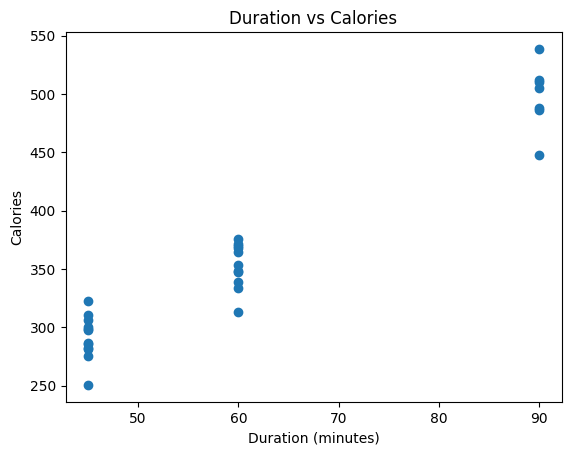

In [12]:
plt.scatter(df["Duration"], df["Calories"])
plt.xlabel("Duration (minutes)")
plt.ylabel("Calories")
plt.title("Duration vs Calories")
plt.show()